<a href="https://colab.research.google.com/github/Nkajabi/cs50.readthedocs.io/blob/main/aiproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

# ============================================================
# CELL 1: INSTALL ADDITIONAL PROJECT LIBRARIES
# IMPORTANT:
# Do NOT upgrade NumPy, Pandas, Pillow, PyTorch or Torchvision.
# Colab already provides these packages.
# ============================================================

%pip install -q datasets xgboost shap scikit-image opencv-python-headless ImageHash


In [3]:

%pip install -q -U datasets huggingface_hub
%pip install -q -U scikit-learn scikit-image
%pip install -q -U xgboost shap
%pip install -q -U opencv-python-headless imagehash
%pip install -q -U seaborn matplotlib pandas numpy tqdm Pillow


In [4]:

# ============================================================
# CELL 2: VERIFY ALL LIBRARIES AND PACKAGE COMPATIBILITY
# ============================================================

import sys
import numpy as np
import pandas as pd
import PIL
import torch
import torchvision
import sklearn
import xgboost
import shap
import datasets
import cv2
import skimage

print("PYTHON:", sys.version)

print("\nPACKAGE VERSIONS")
print("------------------------------")

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Pillow:", PIL.__version__)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("SHAP:", shap.__version__)
print("Hugging Face Datasets:", datasets.__version__)
print("OpenCV:", cv2.__version__)
print("Scikit-image:", skimage.__version__)

print("\nGPU CHECK")
print("------------------------------")

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("WARNING: GPU not enabled.")

print("\nENVIRONMENT CHECK COMPLETED.")


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


PYTHON: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]

PACKAGE VERSIONS
------------------------------
NumPy: 2.4.6
Pandas: 3.1.1
Pillow: 11.3.0
PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
Scikit-learn: 1.9.1
XGBoost: 3.4.1
SHAP: 0.54.1
Hugging Face Datasets: 5.2.0
OpenCV: 5.1.0
Scikit-image: 0.26.0

GPU CHECK
------------------------------
CUDA available: False

ENVIRONMENT CHECK COMPLETED.


In [5]:

# ============================================================
# CELL 3: IMPORT ALL PROJECT LIBRARIES
# ============================================================

import os
import gc
import time
import copy
import random
import warnings
import json
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from tqdm.auto import tqdm
from collections import Counter

# Dataset
from datasets import load_dataset

# Image processing
import cv2
import imagehash
from skimage.feature import hog

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# XGBoost
from xgboost import XGBClassifier

# Deep learning
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from torchvision import transforms, models
from torchvision.models import ResNet50_Weights

# Explainable AI
import shap

warnings.filterwarnings("ignore")

print("All project libraries imported successfully.")


All project libraries imported successfully.


In [6]:

# ============================================================
# CELL 4: PROJECT CONFIGURATION
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

DATASET_NAME = "imadhavan/FER2025"

CLASS_NAMES = [
    "Angry",
    "Disgust",
    "Fear",
    "Happy",
    "Neutral",
    "Sad",
    "Surprise"
]

NUM_CLASSES = len(CLASS_NAMES)

# Initial improved experiment
IMAGES_PER_CLASS = 2000

# Image dimensions
IMAGE_SIZE = 112
HOG_SIZE = (64, 64)
CNN_SIZE = 224

# Training
BATCH_SIZE = 32
EPOCHS = 30
PATIENCE = 6

# Output folder
OUTPUT_DIR = "/content/Emotion_Recognition_Project"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Configuration completed.")
print("Device:", DEVICE)
print("Emotion classes:", CLASS_NAMES)
print("Images per class:", IMAGES_PER_CLASS)
print("Target total:", IMAGES_PER_CLASS * NUM_CLASSES)
print("Output folder:", OUTPUT_DIR)


Configuration completed.
Device: cpu
Emotion classes: ['Angry', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad', 'Surprise']
Images per class: 2000
Target total: 14000
Output folder: /content/Emotion_Recognition_Project


In [7]:

# ============================================================
# CELL 1: INSTALL ADDITIONAL LIBRARIES
# ============================================================

%pip install -q datasets xgboost shap scikit-image opencv-python-headless ImageHash
%pip install -q "bottleneck>=1.5.0"

print("Additional libraries installed.")


Additional libraries installed.


In [8]:

# ============================================================
# CELL 2: VERIFY GPU AND LIBRARIES
# ============================================================

import torch
import torchvision
import numpy as np
import pandas as pd
import xgboost
import shap
import datasets
import cv2
import sklearn

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("XGBoost:", xgboost.__version__)
print("SHAP:", shap.__version__)

print("\nGPU STATUS:")

if torch.cuda.is_available():

    print("GPU ENABLED!")
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)

else:

    print("GPU NOT AVAILABLE.")
    print("Please check Runtime > Change runtime type.")


NumPy: 2.4.6
Pandas: 3.1.1
PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
XGBoost: 3.4.1
SHAP: 0.54.1

GPU STATUS:
GPU NOT AVAILABLE.
Please check Runtime > Change runtime type.


In [9]:

# ============================================================
# CELL 3: INSPECT FER2025 DATASET
# ============================================================

from datasets import load_dataset

DATASET_NAME = "imadhavan/FER2025"

print("Loading FER2025...")

dataset = load_dataset(
    DATASET_NAME,
    split="train",
    streaming=True
)

print("\nChecking the first 20 samples...")

for i, sample in enumerate(dataset.take(20)):

    print("\nSample:", i + 1)

    print("Available fields:", sample.keys())

    print("Image key:", sample.get("__key__"))

    print("Numeric label:", sample.get("cls"))

    image = sample.get("jpg")

    if image is None:
        image = sample.get("image")

    if image is not None:
        print("Image size:", image.size)

print("\nDataset inspection completed.")


Loading FER2025...


README.md:   0%|          | 0.00/2.63k [00:00<?, ?B/s]


Checking the first 20 samples...

Sample: 1
Available fields: dict_keys(['jpg', 'cls', '__key__', '__url__'])
Image key: Angry_000000
Numeric label: 0
Image size: (75, 75)

Sample: 2
Available fields: dict_keys(['jpg', 'cls', '__key__', '__url__'])
Image key: Angry_000001
Numeric label: 0
Image size: (75, 75)

Sample: 3
Available fields: dict_keys(['jpg', 'cls', '__key__', '__url__'])
Image key: Angry_000002
Numeric label: 0
Image size: (75, 75)

Sample: 4
Available fields: dict_keys(['jpg', 'cls', '__key__', '__url__'])
Image key: Angry_000003
Numeric label: 0
Image size: (75, 75)

Sample: 5
Available fields: dict_keys(['jpg', 'cls', '__key__', '__url__'])
Image key: Angry_000004
Numeric label: 0
Image size: (75, 75)

Sample: 6
Available fields: dict_keys(['jpg', 'cls', '__key__', '__url__'])
Image key: Angry_000005
Numeric label: 0
Image size: (75, 75)

Sample: 7
Available fields: dict_keys(['jpg', 'cls', '__key__', '__url__'])
Image key: Angry_000006
Numeric label: 0
Image size: (7

In [10]:

# ============================================================
# CELL 4: CHECK GOOGLE COLAB GPU
# ============================================================

import torch
import subprocess

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():

    print("\nGPU SUCCESSFULLY ENABLED!")

    print(
        "GPU name:",
        torch.cuda.get_device_name(0)
    )

    print(
        "CUDA version:",
        torch.version.cuda
    )

else:

    print("\nGPU IS STILL NOT ENABLED.")

    try:
        subprocess.run(["nvidia-smi"])
    except Exception:
        print("No NVIDIA GPU detected.")


PyTorch version: 2.14.1+cpu
CUDA available: False

GPU IS STILL NOT ENABLED.
No NVIDIA GPU detected.


In [11]:

# ============================================================
# CELL 1: INSTALL ADDITIONAL LIBRARIES
# ============================================================

%pip install -q datasets xgboost shap scikit-image ImageHash

print("Additional libraries installed successfully.")


Additional libraries installed successfully.


In [12]:

# ============================================================
# CELL 2: IMPORT ALL LIBRARIES
# ============================================================

import os
import gc
import time
import copy
import random
import warnings
import json
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from tqdm.auto import tqdm
from collections import Counter

# Dataset
from datasets import load_dataset

# Image processing
import cv2
import imagehash
from skimage.feature import hog

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# XGBoost
from xgboost import XGBClassifier

# Deep learning
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from torchvision import transforms, models
from torchvision.models import ResNet50_Weights

# Explainability
import shap

warnings.filterwarnings("ignore")

print("All libraries imported successfully.")


All libraries imported successfully.


In [13]:

# ============================================================
# CELL 3: CHECK ENVIRONMENT AND HARDWARE
# ============================================================

print("Python environment ready.")

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("XGBoost:", XGBClassifier.__module__)
print("SHAP:", shap.__version__)

if torch.cuda.is_available():

    DEVICE = torch.device("cuda")

    print("\nGPU AVAILABLE")
    print("GPU:", torch.cuda.get_device_name(0))

else:

    DEVICE = torch.device("cpu")

    print("\nCPU MODE")
    print("The project will run using CPU.")

print("Selected device:", DEVICE)


Python environment ready.
NumPy: 2.4.6
Pandas: 3.1.1
PyTorch: 2.14.1+cpu
XGBoost: xgboost.sklearn
SHAP: 0.54.1

CPU MODE
The project will run using CPU.
Selected device: cpu


In [14]:

# ============================================================
# CELL 4: PROJECT CONFIGURATION
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

CLASS_NAMES = [
    "Angry",
    "Disgust",
    "Fear",
    "Happy",
    "Neutral",
    "Sad",
    "Surprise"
]

NUM_CLASSES = len(CLASS_NAMES)

DATASET_NAME = "imadhavan/FER2025"

# Initial sample size per emotion
# Increase after confirming that the pipeline works.
IMAGES_PER_CLASS = 1000

# Image dimensions
IMAGE_SIZE = 112
HOG_SIZE = (64, 64)
CNN_SIZE = 224

# Training
BATCH_SIZE = 16 if DEVICE.type == "cpu" else 32

EPOCHS = 8 if DEVICE.type == "cpu" else 30

PATIENCE = 4 if DEVICE.type == "cpu" else 7

OUTPUT_DIR = "/content/Emotion_Recognition_Project"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Project configuration completed.")
print("Classes:", CLASS_NAMES)
print("Images per class:", IMAGES_PER_CLASS)
print("Target images:", IMAGES_PER_CLASS * NUM_CLASSES)
print("Training epochs:", EPOCHS)
print("Device:", DEVICE)


Project configuration completed.
Classes: ['Angry', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad', 'Surprise']
Images per class: 1000
Target images: 7000
Training epochs: 8
Device: cpu


Dataset loaded successfully.
Dataset fields: dict_keys(['jpg', 'cls', '__key__', '__url__'])
Image key: Angry_000000
Numeric label: 0
Image dimensions: (75, 75)


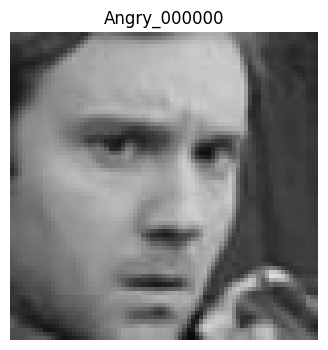

In [15]:

# ============================================================
# CELL 5: LOAD FER2025 DATASET
# ============================================================

dataset = load_dataset(
    DATASET_NAME,
    split="train",
    streaming=True
)

print("Dataset loaded successfully.")

first_sample = next(iter(dataset))

print("Dataset fields:", first_sample.keys())
print("Image key:", first_sample["__key__"])
print("Numeric label:", first_sample["cls"])
print("Image dimensions:", first_sample["jpg"].size)

plt.figure(figsize=(4, 4))
plt.imshow(first_sample["jpg"])
plt.title(first_sample["__key__"])
plt.axis("off")
plt.show()


In [16]:

# ============================================================
# CELL 6: VERIFY ALL SEVEN EMOTION LABELS
# ============================================================

label_mapping = {
    name: index
    for index, name in enumerate(CLASS_NAMES)
}

verified = {}

for sample in dataset:

    key = sample["__key__"]
    emotion = key.split("_")[0]

    if emotion not in label_mapping:
        continue

    actual_label = int(sample["cls"])
    expected_label = label_mapping[emotion]

    if actual_label != expected_label:
        raise ValueError(
            f"Incorrect label for {key}: "
            f"{actual_label} != {expected_label}"
        )

    verified[emotion] = actual_label

    if len(verified) == NUM_CLASSES:
        break

print("VERIFIED EMOTION LABELS")

for emotion, label in verified.items():
    print(emotion, "=", label)

assert len(verified) == NUM_CLASSES, (
    "Not all seven emotion classes were verified."
)

print("\nAll seven labels verified.")


VERIFIED EMOTION LABELS
Angry = 0
Disgust = 1
Fear = 2
Happy = 3
Neutral = 4
Sad = 5
Surprise = 6

All seven labels verified.


In [17]:

# ============================================================
# CELL 7: COLLECT BALANCED EMOTION IMAGES
# ============================================================

images = []
labels = []
image_keys = []

class_counts = {
    i: 0 for i in range(NUM_CLASSES)
}

dataset = load_dataset(
    DATASET_NAME,
    split="train",
    streaming=True
)

print("Collecting images. Please wait...")

for sample in tqdm(dataset):

    if all(
        class_counts[i] >= IMAGES_PER_CLASS
        for i in range(NUM_CLASSES)
    ):
        break

    try:

        key = sample["__key__"]
        emotion = key.split("_")[0]

        if emotion not in label_mapping:
            continue

        label = int(sample["cls"])

        if label != label_mapping[emotion]:
            continue

        if class_counts[label] >= IMAGES_PER_CLASS:
            continue

        image = sample["jpg"].convert("RGB")

        image = image.resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.LANCZOS
        )

        array = np.asarray(
            image,
            dtype=np.uint8
        )

        images.append(array)
        labels.append(label)
        image_keys.append(key)

        class_counts[label] += 1

    except Exception as error:
        continue

X_images = np.asarray(images, dtype=np.uint8)
y = np.asarray(labels, dtype=np.int64)

print("\nDATA COLLECTION FINISHED")
print("Image array:", X_images.shape)
print("Label array:", y.shape)

for i, name in enumerate(CLASS_NAMES):
    print(name, ":", class_counts[i])

if len(y) == 0:
    raise ValueError("No images were collected.")

if min(class_counts.values()) < IMAGES_PER_CLASS:
    print("WARNING: Some classes did not reach the target.")


0it [00:00, ?it/s]


DATA COLLECTION FINISHED
Image array: (7000, 112, 112, 3)
Label array: (7000,)
Angry : 1000
Disgust : 1000
Fear : 1000
Happy : 1000
Neutral : 1000
Sad : 1000
Surprise : 1000


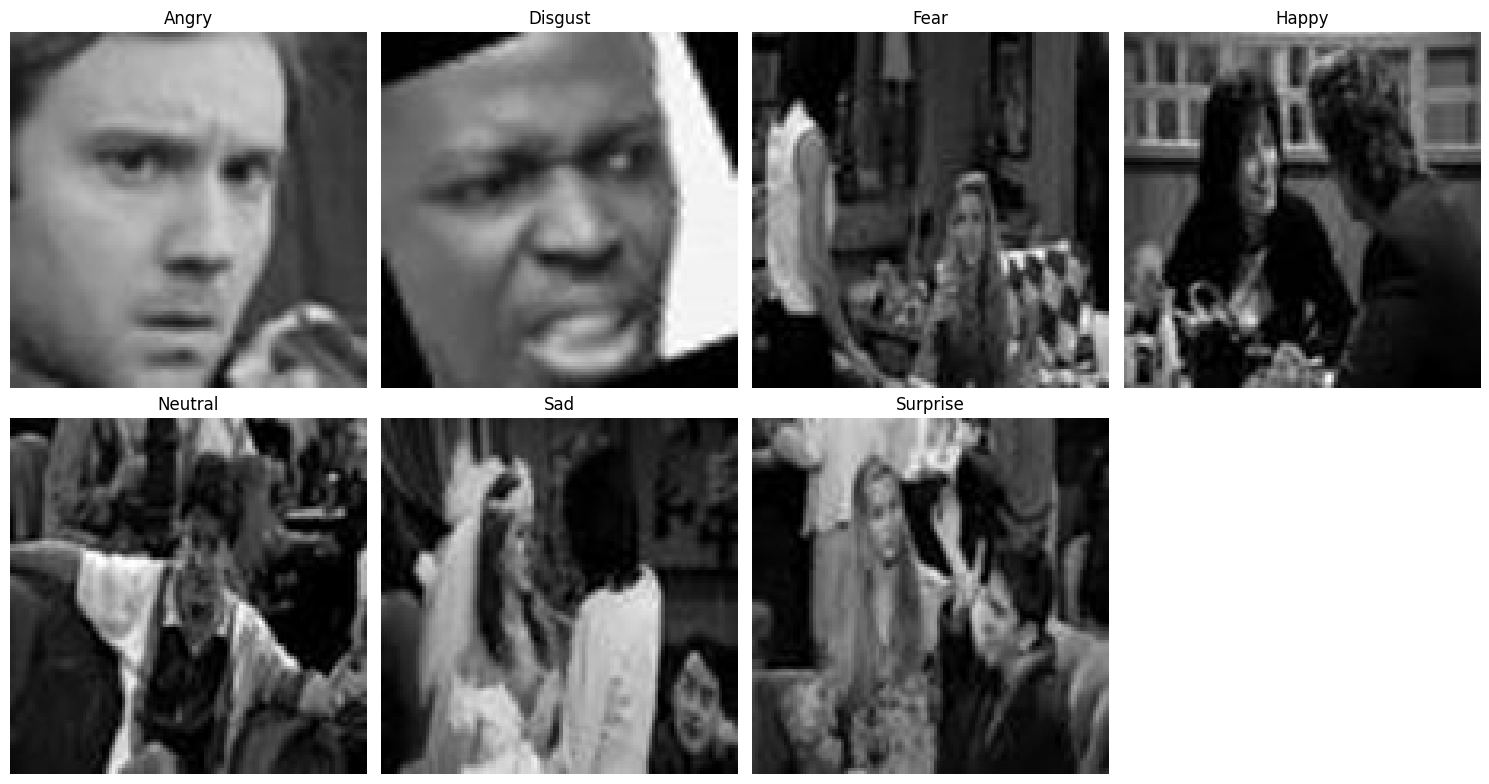

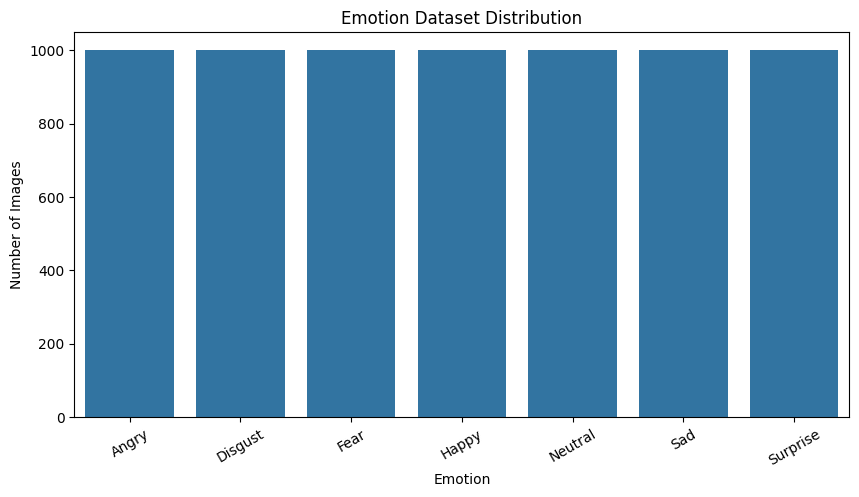

In [18]:

# ============================================================
# CELL 8: DISPLAY SAMPLE IMAGES
# ============================================================

plt.figure(figsize=(15, 8))

for class_id, name in enumerate(CLASS_NAMES):

    indices = np.where(y == class_id)[0]

    if len(indices) == 0:
        continue

    plt.subplot(2, 4, class_id + 1)

    plt.imshow(X_images[indices[0]])
    plt.title(name)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Class distribution

counts = [
    np.sum(y == i)
    for i in range(NUM_CLASSES)
]

plt.figure(figsize=(10, 5))

sns.barplot(
    x=CLASS_NAMES,
    y=counts
)

plt.title("Emotion Dataset Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)

plt.show()


In [19]:

# ============================================================
# CELL 9: REMOVE EXACT PERCEPTUAL-HASH DUPLICATES
# ============================================================

unique_indices = []
seen_hashes = set()

for i, image_array in enumerate(
    tqdm(X_images, desc="Checking duplicates")
):

    pil_image = Image.fromarray(image_array)

    current_hash = str(
        imagehash.phash(pil_image)
    )

    if current_hash not in seen_hashes:

        seen_hashes.add(current_hash)
        unique_indices.append(i)

X_images = X_images[unique_indices]
y = y[unique_indices]

print("Images after duplicate removal:", len(y))

print(
    "Class distribution:",
    Counter(y)
)


Checking duplicates:   0%|          | 0/7000 [00:00<?, ?it/s]

Images after duplicate removal: 6685
Class distribution: Counter({np.int64(3): 992, np.int64(4): 983, np.int64(0): 976, np.int64(6): 969, np.int64(5): 966, np.int64(2): 941, np.int64(1): 858})


In [20]:

# ============================================================
# CELL 10: STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ============================================================

indices = np.arange(len(y))

train_indices, remaining_indices = train_test_split(
    indices,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

val_indices, test_indices = train_test_split(
    remaining_indices,
    test_size=0.50,
    stratify=y[remaining_indices],
    random_state=SEED
)

X_train_images = X_images[train_indices]
X_val_images = X_images[val_indices]
X_test_images = X_images[test_indices]

y_train = y[train_indices]
y_val = y[val_indices]
y_test = y[test_indices]

print("Training images:", len(y_train))
print("Validation images:", len(y_val))
print("Testing images:", len(y_test))

print("\nTraining distribution:")

for i, name in enumerate(CLASS_NAMES):
    print(name, np.sum(y_train == i))


Training images: 5348
Validation images: 668
Testing images: 669

Training distribution:
Angry 781
Disgust 686
Fear 753
Happy 794
Neutral 786
Sad 773
Surprise 775


In [21]:

# ============================================================
# CELL 11: HOG FEATURE EXTRACTION
# ============================================================

def extract_hog_features(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    gray = cv2.resize(
        gray,
        HOG_SIZE
    )

    features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        transform_sqrt=True,
        feature_vector=True
    )

    return features.astype(np.float32)


def extract_feature_set(images, name):

    result = []

    for image in tqdm(images, desc=name):

        result.append(
            extract_hog_features(image)
        )

    return np.asarray(
        result,
        dtype=np.float32
    )


X_train_hog = extract_feature_set(
    X_train_images,
    "Training HOG"
)

X_val_hog = extract_feature_set(
    X_val_images,
    "Validation HOG"
)

X_test_hog = extract_feature_set(
    X_test_images,
    "Testing HOG"
)

print("Training HOG shape:", X_train_hog.shape)


Training HOG:   0%|          | 0/5348 [00:00<?, ?it/s]

Validation HOG:   0%|          | 0/668 [00:00<?, ?it/s]

Testing HOG:   0%|          | 0/669 [00:00<?, ?it/s]

Training HOG shape: (5348, 1764)


In [22]:

# ============================================================
# CELL 12: STANDARDIZE HOG FEATURES
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_hog
).astype(np.float32)

X_val_scaled = scaler.transform(
    X_val_hog
).astype(np.float32)

X_test_scaled = scaler.transform(
    X_test_hog
).astype(np.float32)

print("HOG scaling completed.")


HOG scaling completed.


In [23]:

# ============================================================
# CELL 13: RANDOM FOREST + HOG
# ============================================================

rf_configs = [
    {
        "n_estimators": 300,
        "max_depth": 30,
        "min_samples_leaf": 1
    },
    {
        "n_estimators": 500,
        "max_depth": None,
        "min_samples_leaf": 1
    },
    {
        "n_estimators": 500,
        "max_depth": 40,
        "min_samples_leaf": 2
    }
]

best_rf = None
best_rf_score = -1

for config in rf_configs:

    print("\nTesting:", config)

    candidate = RandomForestClassifier(
        **config,
        max_features="sqrt",
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=SEED
    )

    start = time.time()

    candidate.fit(
        X_train_scaled,
        y_train
    )

    elapsed = time.time() - start

    predictions = candidate.predict(
        X_val_scaled
    )

    score = f1_score(
        y_val,
        predictions,
        average="macro"
    )

    print("Validation macro F1:", round(score, 4))
    print("Training time:", round(elapsed, 2), "seconds")

    if score > best_rf_score:

        best_rf_score = score
        best_rf = candidate

rf_model = best_rf

print("\nBest Random Forest selected.")
print("Validation macro F1:", best_rf_score)



Testing: {'n_estimators': 300, 'max_depth': 30, 'min_samples_leaf': 1}
Validation macro F1: 0.5574
Training time: 117.25 seconds

Testing: {'n_estimators': 500, 'max_depth': None, 'min_samples_leaf': 1}
Validation macro F1: 0.5658
Training time: 153.01 seconds

Testing: {'n_estimators': 500, 'max_depth': 40, 'min_samples_leaf': 2}
Validation macro F1: 0.5596
Training time: 120.18 seconds

Best Random Forest selected.
Validation macro F1: 0.5657892661924412


In [ ]:

# ============================================================
# CELL 14: XGBOOST + HOG
# ============================================================

xgb_device = (
    "cuda" if torch.cuda.is_available() else "cpu"
)

xgb_configs = [
    {
        "n_estimators": 300,
        "max_depth": 5,
        "learning_rate": 0.05
    },
    {
        "n_estimators": 500,
        "max_depth": 6,
        "learning_rate": 0.05
    }
]

best_xgb = None
best_xgb_score = -1

for config in xgb_configs:

    print("\nTesting:", config)

    candidate = XGBClassifier(
        **config,
        subsample=0.85,
        colsample_bytree=0.85,
        min_child_weight=2,
        reg_lambda=2,
        objective="multi:softprob",
        num_class=NUM_CLASSES,
        eval_metric="mlogloss",
        tree_method="hist",
        device=xgb_device,
        n_jobs=4,
        random_state=SEED
    )

    start = time.time()

    try:

        candidate.fit(
            X_train_scaled,
            y_train,
            eval_set=[(X_val_scaled, y_val)],
            verbose=False
        )

    except Exception as error:

        if xgb_device == "cuda":

            print("CUDA failed. Retrying on CPU.")

            xgb_device = "cpu"
            candidate.set_params(device="cpu")

            candidate.fit(
                X_train_scaled,
                y_train,
                eval_set=[(X_val_scaled, y_val)],
                verbose=False
            )

        else:
            raise

    elapsed = time.time() - start

    predictions = candidate.predict(
        X_val_scaled
    )

    score = f1_score(
        y_val,
        predictions,
        average="macro"
    )

    print("Validation macro F1:", round(score, 4))
    print("Training time:", round(elapsed, 2), "seconds")

    if score > best_xgb_score:

        best_xgb_score = score
        best_xgb = candidate

xgb_model = best_xgb

print("\nBest XGBoost selected.")
print("Validation macro F1:", best_xgb_score)
print("Device:", xgb_device)



Testing: {'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.05}
Validation macro F1: 0.4994
Training time: 766.86 seconds

Testing: {'n_estimators': 500, 'max_depth': 6, 'learning_rate': 0.05}


In [ ]:

# ============================================================
# CELL 15: IMAGE AUGMENTATION
# ============================================================

train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

print("Image transformations ready.")


In [ ]:

# ============================================================
# CELL 16: CREATE PYTORCH DATASETS AND DATALOADERS
# ============================================================

class EmotionDataset(Dataset):

    def __init__(self, images, labels, transform):

        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):

        image = Image.fromarray(
            self.images[index]
        ).convert("RGB")

        label = int(self.labels[index])

        return self.transform(image), label


train_dataset = EmotionDataset(
    X_train_images,
    y_train,
    train_transform
)

val_dataset = EmotionDataset(
    X_val_images,
    y_val,
    eval_transform
)

test_dataset = EmotionDataset(
    X_test_images,
    y_test,
    eval_transform
)

# Windows/Colab-compatible conservative worker setting
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

print("PyTorch data loaders created.")


In [ ]:

# ============================================================
# CELL 17: LOAD RESNET-50
# ============================================================

weights = ResNet50_Weights.DEFAULT

resnet_model = models.resnet50(
    weights=weights
)

# Replace the original 1000-class layer
resnet_model.fc = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(
        resnet_model.fc.in_features,
        NUM_CLASSES
    )
)

# Freeze early layers initially
for parameter in resnet_model.parameters():
    parameter.requires_grad = False

# Train final residual block and classifier
for parameter in resnet_model.layer4.parameters():
    parameter.requires_grad = True

for parameter in resnet_model.fc.parameters():
    parameter.requires_grad = True

resnet_model = resnet_model.to(DEVICE)

print("ResNet-50 loaded.")
print("Trainable final block and classifier.")


In [ ]:

# ============================================================
# CELL 18: RESNET TRAINING CONFIGURATION
# ============================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.05
)

optimizer = optim.AdamW(
    [
        {
            "params": resnet_model.layer4.parameters(),
            "lr": 1e-5
        },
        {
            "params": resnet_model.fc.parameters(),
            "lr": 2e-4
        }
    ],
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

amp_enabled = DEVICE.type == "cuda"

amp_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=amp_enabled
)

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
best_weights = copy.deepcopy(
    resnet_model.state_dict()
)

epochs_without_improvement = 0

print("ResNet training configuration ready.")


In [ ]:

# ============================================================
# CELL 19: TRAINING FUNCTIONS
# ============================================================

def train_one_epoch(model, loader):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for batch_images, batch_labels in tqdm(
        loader,
        leave=False
    ):

        batch_images = batch_images.to(DEVICE)
        batch_labels = batch_labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=DEVICE.type,
            enabled=amp_enabled
        ):

            outputs = model(batch_images)

            loss = criterion(
                outputs,
                batch_labels
            )

        amp_scaler.scale(loss).backward()

        amp_scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0
        )

        amp_scaler.step(optimizer)
        amp_scaler.update()

        total_loss += loss.item() * batch_labels.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == batch_labels
        ).sum().item()

        total += batch_labels.size(0)

    return total_loss / total, correct / total


def validate_one_epoch(model, loader):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for batch_images, batch_labels in loader:

            batch_images = batch_images.to(DEVICE)
            batch_labels = batch_labels.to(DEVICE)

            with torch.autocast(
                device_type=DEVICE.type,
                enabled=amp_enabled
            ):

                outputs = model(batch_images)

                loss = criterion(
                    outputs,
                    batch_labels
                )

            total_loss += loss.item() * batch_labels.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (
                predictions == batch_labels
            ).sum().item()

            total += batch_labels.size(0)

    return total_loss / total, correct / total


print("Training functions ready.")


In [ ]:

# ============================================================
# CELL 20: TRAIN RESNET-50
# ============================================================

start_time = time.time()

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_loss, train_acc = train_one_epoch(
        resnet_model,
        train_loader
    )

    val_loss, val_acc = validate_one_epoch(
        resnet_model,
        val_loader
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)

    print(
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: {train_acc:.4f}"
    )

    print(
        f"Validation loss: {val_loss:.4f} | "
        f"Validation accuracy: {val_acc:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_weights = copy.deepcopy(
            resnet_model.state_dict()
        )

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:

        print("Early stopping activated.")
        break

resnet_model.load_state_dict(best_weights)

resnet_training_time = time.time() - start_time

print("\nResNet training completed.")
print("Time:", round(resnet_training_time, 2), "seconds")


In [ ]:

# ============================================================
# CELL 21: RESNET TRAINING CURVES
# ============================================================

epochs_completed = range(
    1,
    len(history["train_loss"]) + 1
)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(
    epochs_completed,
    history["train_loss"],
    label="Training loss"
)

plt.plot(
    epochs_completed,
    history["val_loss"],
    label="Validation loss"
)

plt.title("ResNet-50 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)

plt.plot(
    epochs_completed,
    history["train_accuracy"],
    label="Training accuracy"
)

plt.plot(
    epochs_completed,
    history["val_accuracy"],
    label="Validation accuracy"
)

plt.title("ResNet-50 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# CELL 22: GENERATE TEST PREDICTIONS
# ============================================================

print("Generating Random Forest predictions...")

rf_predictions = rf_model.predict(X_test_scaled)
rf_probabilities = rf_model.predict_proba(X_test_scaled)

print("Generating XGBoost predictions...")

xgb_predictions = xgb_model.predict(X_test_scaled)
xgb_probabilities = xgb_model.predict_proba(X_test_scaled)

print("Generating ResNet predictions...")

resnet_model.eval()

resnet_predictions = []
resnet_probabilities = []

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

start = time.time()

with torch.no_grad():

    for batch_images, batch_labels in tqdm(test_loader):

        batch_images = batch_images.to(DEVICE)

        with torch.autocast(
            device_type=DEVICE.type,
            enabled=amp_enabled
        ):

            outputs = resnet_model(batch_images)

        probabilities = torch.softmax(
            outputs.float(),
            dim=1
        )

        resnet_predictions.extend(
            probabilities.argmax(dim=1).cpu().numpy()
        )

        resnet_probabilities.extend(
            probabilities.cpu().numpy()
        )

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

resnet_inference_seconds = (
    time.time() - start
)

resnet_predictions = np.asarray(
    resnet_predictions
)

resnet_probabilities = np.asarray(
    resnet_probabilities
)

print("All predictions completed.")


In [ ]:

# ============================================================
# CELL 23: EVALUATE ACCURACY, PRECISION, RECALL AND F1
# ============================================================

def evaluate_model(
    name,
    true_labels,
    predictions,
    probabilities
):

    return {
        "Model": name,

        "Accuracy": accuracy_score(
            true_labels,
            predictions
        ),

        "Macro Precision": precision_score(
            true_labels,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Weighted Precision": precision_score(
            true_labels,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "Macro Recall": recall_score(
            true_labels,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Weighted Recall": recall_score(
            true_labels,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "Macro F1": f1_score(
            true_labels,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            true_labels,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "ROC AUC": roc_auc_score(
            true_labels,
            probabilities,
            multi_class="ovr",
            average="weighted",
            labels=np.arange(NUM_CLASSES)
        )
    }


comparison = pd.DataFrame([

    evaluate_model(
        "Random Forest + HOG",
        y_test,
        rf_predictions,
        rf_probabilities
    ),

    evaluate_model(
        "XGBoost + HOG",
        y_test,
        xgb_predictions,
        xgb_probabilities
    ),

    evaluate_model(
        "ResNet-50",
        y_test,
        resnet_predictions,
        resnet_probabilities
    )

])

display(
    comparison.style.format({
        column: "{:.4f}"
        for column in comparison.columns
        if column != "Model"
    })
)

comparison.to_csv(
    os.path.join(OUTPUT_DIR, "model_comparison.csv"),
    index=False
)


In [ ]:

# ============================================================
# CELL 24: CLASSIFICATION REPORTS
# ============================================================

prediction_sets = {
    "Random Forest + HOG": rf_predictions,
    "XGBoost + HOG": xgb_predictions,
    "ResNet-50": resnet_predictions
}

for name, predictions in prediction_sets.items():

    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)

    print(
        classification_report(
            y_test,
            predictions,
            labels=np.arange(NUM_CLASSES),
            target_names=CLASS_NAMES,
            digits=4,
            zero_division=0
        )
    )


In [ ]:

# ============================================================
# CELL 25: CONFUSION MATRICES
# ============================================================

for name, predictions in prediction_sets.items():

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=np.arange(NUM_CLASSES),
        normalize="true"
    )

    plt.figure(figsize=(9, 7))

    sns.heatmap(
        cm,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.title(f"Normalized Confusion Matrix: {name}")
    plt.xlabel("Predicted Emotion")
    plt.ylabel("Actual Emotion")

    plt.tight_layout()
    plt.show()


In [ ]:

# ============================================================
# CELL 26: MODEL PERFORMANCE COMPARISON
# ============================================================

metrics_to_plot = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1"
]

comparison_long = comparison.melt(
    id_vars="Model",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(14, 6))

sns.barplot(
    data=comparison_long,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.ylim(0, 1)
plt.title("Comparison of Emotion Recognition Models")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(title="Model")

plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# CELL 27: SHAP EXPLANATION FOR XGBOOST
# ============================================================

# Use a small sample to avoid excessive memory usage
sample_count = min(100, len(X_test_scaled))

X_shap = X_test_scaled[:sample_count]

explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_shap)

print("SHAP calculation completed.")

# Support both list-based and array-based SHAP outputs
if isinstance(shap_values, list):

    for class_id, class_values in enumerate(shap_values):

        print("Explaining:", CLASS_NAMES[class_id])

        shap.summary_plot(
            class_values,
            X_shap,
            show=True,
            max_display=15
        )

else:

    shap_array = np.asarray(shap_values)

    print("SHAP output shape:", shap_array.shape)

    if shap_array.ndim == 3:

        for class_id in range(NUM_CLASSES):

            print("Explaining:", CLASS_NAMES[class_id])

            shap.summary_plot(
                shap_array[:, :, class_id],
                X_shap,
                show=True,
                max_display=15
            )

    elif shap_array.ndim == 2:

        shap.summary_plot(
            shap_array,
            X_shap,
            show=True,
            max_display=15
        )


In [ ]:

# ============================================================
# CELL 28: GRAD-CAM EXPLANATION FOR RESNET-50
# ============================================================

class GradCAM:

    def __init__(self, model, target_layer):

        self.model = model
        self.activations = None
        self.gradients = None

        self.handle = target_layer.register_forward_hook(
            self.forward_hook
        )

    def forward_hook(self, module, inputs, output):

        self.activations = output

        output.register_hook(
            self.save_gradient
        )

    def save_gradient(self, gradient):

        self.gradients = gradient

    def generate(self, image_tensor, class_index=None):

        self.model.eval()
        self.model.zero_grad(set_to_none=True)

        output = self.model(image_tensor)

        if class_index is None:
            class_index = output.argmax(dim=1).item()

        score = output[:, class_index].sum()

        score.backward()

        weights = self.gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        cam = (
            weights * self.activations
        ).sum(dim=1)

        cam = torch.relu(cam)

        cam = cam[0].detach().cpu().numpy()

        cam = cv2.resize(
            cam,
            (224, 224)
        )

        cam = cam - cam.min()

        if cam.max() > 0:
            cam = cam / cam.max()

        return cam, class_index


gradcam = GradCAM(
    resnet_model,
    resnet_model.layer4[-1]
)

# Show an example from the test set
example_index = 0

example_image = X_test_images[example_index]

input_tensor, true_label = test_dataset[example_index]

input_tensor = input_tensor.unsqueeze(0).to(DEVICE)

heatmap, predicted_class = gradcam.generate(
    input_tensor
)

heatmap_color = cv2.applyColorMap(
    np.uint8(255 * heatmap),
    cv2.COLORMAP_JET
)

original = cv2.resize(
    example_image,
    (224, 224)
)

overlay = cv2.addWeighted(
    original,
    0.6,
    heatmap_color,
    0.4,
    0
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap="jet")
plt.title("Grad-CAM heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title(
    f"Actual: {CLASS_NAMES[true_label]}\n"
    f"Predicted: {CLASS_NAMES[predicted_class]}"
)
plt.axis("off")

plt.tight_layout()
plt.show()

gradcam.handle.remove()


In [ ]:

# ============================================================
# CELL 29: SAVE TRAINED MODELS AND RESULTS
# ============================================================

# Random Forest
joblib.dump(
    rf_model,
    os.path.join(OUTPUT_DIR, "random_forest_hog.pkl")
)

# XGBoost
xgb_model.save_model(
    os.path.join(OUTPUT_DIR, "xgboost_hog.json")
)

# ResNet
torch.save(
    resnet_model.state_dict(),
    os.path.join(OUTPUT_DIR, "resnet50.pth")
)

# Scaler
joblib.dump(
    scaler,
    os.path.join(OUTPUT_DIR, "hog_scaler.pkl")
)

# Metrics
comparison.to_csv(
    os.path.join(OUTPUT_DIR, "model_comparison.csv"),
    index=False
)

# Training history
with open(
    os.path.join(OUTPUT_DIR, "resnet_training_history.json"),
    "w"
) as file:

    json.dump(history, file)

print("All models and results saved.")
print("Output folder:", OUTPUT_DIR)


In [ ]:

# ============================================================
# CELL 30: CREATE DOWNLOADABLE PROJECT ZIP
# ============================================================

import shutil

zip_path = shutil.make_archive(
    "/content/Emotion_Recognition_Project",
    "zip",
    OUTPUT_DIR
)

print("Project ZIP created:")
print(zip_path)

from google.colab import files

files.download(zip_path)
